Cargar archivo csv e importar librerias

In [9]:
import pandas as pd
import matplotlib.pyplot as plt


df = pd.read_csv("/content/Walmart_Sales.csv")
df.head()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,12-02-2010,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,19-02-2010,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,26-02-2010,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,05-03-2010,1554806.68,0,46.50,2.625,211.350143,8.106


Comprobación carga correcta

In [4]:
print("Filas y columnas:", df.shape)
print("Nombres de las columnas:", df.columns.tolist())

df.info()

Filas y columnas: (6435, 8)
Nombres de las columnas: ['Store', 'Date', 'Weekly_Sales', 'Holiday_Flag', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Store         6435 non-null   int64  
 1   Date          6435 non-null   object 
 2   Weekly_Sales  6435 non-null   float64
 3   Holiday_Flag  6435 non-null   int64  
 4   Temperature   6435 non-null   float64
 5   Fuel_Price    6435 non-null   float64
 6   CPI           6435 non-null   float64
 7   Unemployment  6435 non-null   float64
dtypes: float64(5), int64(2), object(1)
memory usage: 402.3+ KB


Cambio DATE formato de texto a fecha

In [16]:
df["Date"] = pd.to_datetime(df["Date"], format="%d-%m-%Y")

# Comprobar la conversión
print(df["Date"].dtype)
df[["Store", "Date", "Weekly_Sales"]].head()

datetime64[ns]


,Store,Date,Weekly_Sales
0,1,2010-02-05,1643690.90
1,1,2010-02-12,1641957.44
2,1,2010-02-19,1611968.17
3,1,2010-02-26,1409727.59
4,1,2010-03-05,1554806.68


Ver duplicados

In [6]:
# Filas idénticas en todas las columnas
print("Filas duplicadas:", df.duplicated().sum())

# Registros repetidos para la misma tienda y fecha
print(
    "Combinaciones Store-Date duplicadas:",
    df.duplicated(subset=["Store", "Date"]).sum()
)

Filas duplicadas: 0
Combinaciones Store-Date duplicadas: 0


Revisar valores de las variables

In [7]:
# Comprobar los valores de la variable de festivos
print("Valores de Holiday_Flag:", df["Holiday_Flag"].unique())

# Revisar mínimos, máximos y distribución de las variables numéricas
df.describe()

Valores de Holiday_Flag: [0 1]


,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
count,6435.000000,6435,6.435000e+03,6435.000000,6435.000000,6435.000000,6435.000000,6435.000000
mean,23.000000,2011-06-17 00:00:00,1.046965e+06,0.069930,60.663782,3.358607,171.578394,7.999151
min,1.000000,2010-02-05 00:00:00,2.099862e+05,0.000000,-2.060000,2.472000,126.064000,3.879000
25%,12.000000,2010-10-08 00:00:00,5.533501e+05,0.000000,47.460000,2.933000,131.735000,6.891000
50%,23.000000,2011-06-17 00:00:00,9.607460e+05,0.000000,62.670000,3.445000,182.616521,7.874000
75%,34.000000,2012-02-24 00:00:00,1.420159e+06,0.000000,74.940000,3.735000,212.743293,8.622000
max,45.000000,2012-10-26 00:00:00,3.818686e+06,1.000000,100.140000,4.468000,227.232807,14.313000
std,12.988182,NaN,5.643666e+05,0.255049,18.444933,0.459020,39.356712,1.875885


Comprobar si todas las tiendas tienen las mismas semanas y si hay huecos entre fechas

In [8]:
# Resumen de cobertura temporal por tienda
cobertura = df.groupby("Store").agg(
    registros=("Date", "size"),
    primera_fecha=("Date", "min"),
    ultima_fecha=("Date", "max")
)

display(cobertura)

# Días entre registros consecutivos de cada tienda
datos_ordenados = df.sort_values(["Store", "Date"])

intervalos = (
    datos_ordenados.groupby("Store")["Date"]
    .diff()
    .dt.days
)

print("Intervalos entre registros, en días:")
print(intervalos.value_counts().sort_index())

,registros,primera_fecha,ultima_fecha
Store,,,
1,143,2010-02-05,2012-10-26
2,143,2010-02-05,2012-10-26
3,143,2010-02-05,2012-10-26
4,143,2010-02-05,2012-10-26
5,143,2010-02-05,2012-10-26
6,143,2010-02-05,2012-10-26
7,143,2010-02-05,2012-10-26
8,143,2010-02-05,2012-10-26
9,143,2010-02-05,2012-10-26


Intervalos entre registros, en días:
Date
7.0    6390
Name: count, dtype: int64


Valore atípicos usando boxplot

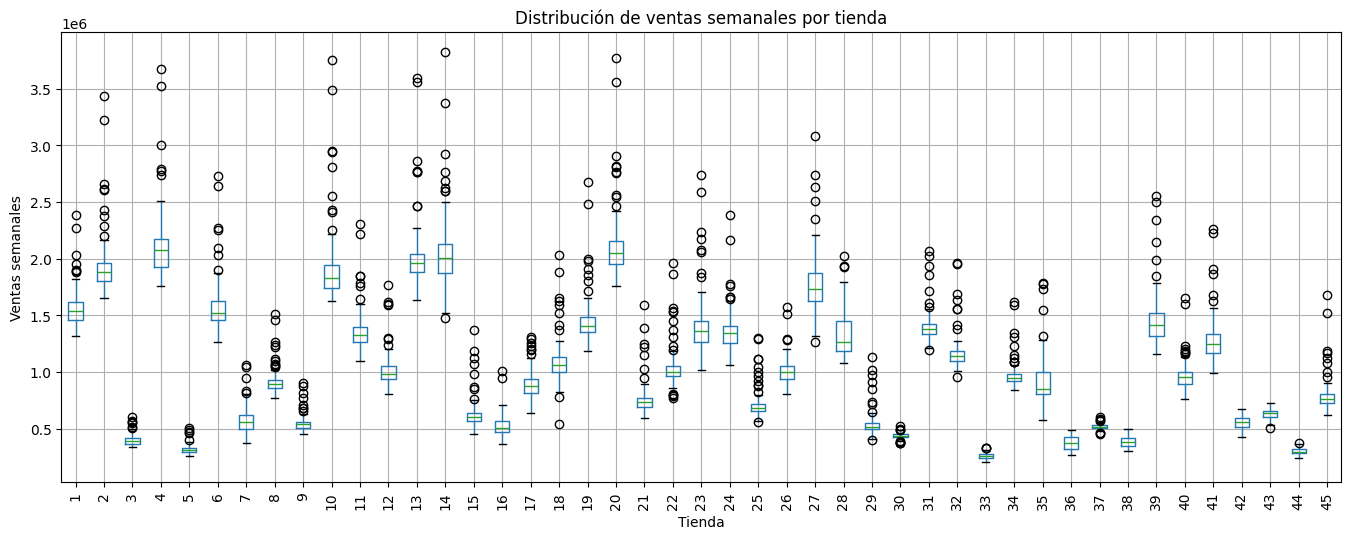

In [10]:
df.boxplot(
    column="Weekly_Sales",
    by="Store",
    figsize=(16, 6),
    rot=90
)

plt.title("Distribución de ventas semanales por tienda")
plt.suptitle("")
plt.xlabel("Tienda")
plt.ylabel("Ventas semanales")
plt.show()

Valores atípicos usando IQR

In [11]:
# Calcular los cuartiles de ventas dentro de cada tienda
ventas_por_tienda = df.groupby("Store")["Weekly_Sales"]

q1 = ventas_por_tienda.transform("quantile", q=0.25)
q3 = ventas_por_tienda.transform("quantile", q=0.75)

# Calcular el rango intercuartílico y los límites
iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

# Seleccionar las semanas con ventas fuera de esos límites
es_atipico = (
    (df["Weekly_Sales"] < limite_inferior)
    | (df["Weekly_Sales"] > limite_superior)
)

outliers = df.loc[es_atipico].copy()

print("Registros con ventas atípicas:", len(outliers))

# Mostrar los 15 de mayores ventas
display(
    outliers.sort_values("Weekly_Sales", ascending=False)
    [["Store", "Date", "Weekly_Sales", "Holiday_Flag"]]
    .head(15)
)

Registros con ventas atípicas: 300


,Store,Date,Weekly_Sales,Holiday_Flag
1905,14,24-12-2010,3818686.45,0
2763,20,24-12-2010,3766687.43,0
1333,10,24-12-2010,3749057.69,0
527,4,23-12-2011,3676388.98,0
1762,13,24-12-2010,3595903.20,0
1814,13,23-12-2011,3556766.03,0
2815,20,23-12-2011,3555371.03,0
475,4,24-12-2010,3526713.39,0
1385,10,23-12-2011,3487986.89,0
189,2,24-12-2010,3436007.68,0


Ver los limites (tanto inferior como superior de cada tienda)

In [12]:
limites_por_tienda = pd.DataFrame({
    "Store": df["Store"],
    "Lower_Limit": limite_inferior,
    "Upper_Limit": limite_superior
}).drop_duplicates().sort_values("Store")

display(limites_por_tienda)

,Store,Lower_Limit,Upper_Limit
0,1,1.222924e+06,1.850073e+06
143,2,1.573362e+06,2.187065e+06
286,3,2.885125e+05,5.001075e+05
429,4,1.561470e+06,2.543180e+06
572,5,2.419491e+05,3.826074e+05
715,6,1.203299e+06,1.877561e+06
858,7,3.122384e+05,8.066777e+05
1001,8,7.462320e+05,1.038695e+06
1144,9,4.266940e+05,6.402212e+05
1287,10,1.435762e+06,2.249120e+06


Crear columna en indicando si el valor es atípico o no

In [14]:
# Identificar las ventas atípicas para poder revisarlas después
df["Sales_Outlier"] = es_atipico

Crear variables año, mes, trimestre e ISO_semana de cada fecha

In [17]:
# Crear variables a partir de la fecha
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Quarter"] = df["Date"].dt.quarter
df["ISO_Week"] = df["Date"].dt.isocalendar().week

# Revisar el resultado
display(
    df[[
        "Date", "Year", "Month",
        "Quarter", "ISO_Week", "Sales_Outlier"
    ]].head()
)

,Date,Year,Month,Quarter,ISO_Week,Sales_Outlier
0,2010-02-05,2010,2,1,5,False
1,2010-02-12,2010,2,1,6,False
2,2010-02-19,2010,2,1,7,False
3,2010-02-26,2010,2,1,8,False
4,2010-03-05,2010,3,1,9,False


Ordenar y Revisar resultado de registros

In [18]:
# Ordenar por tienda y fecha
df = df.sort_values(["Store", "Date"]).reset_index(drop=True)

# Comprobaciones finales
print("Filas y columnas:", df.shape)
print("Valores nulos:", df.isna().sum().sum())
print("Duplicados por tienda y fecha:",
      df.duplicated(subset=["Store", "Date"]).sum())
print("Ventas atípicas:", df["Sales_Outlier"].sum())

Filas y columnas: (6435, 13)
Valores nulos: 0
Duplicados por tienda y fecha: 0
Ventas atípicas: 300


Guardar datos y cambiar formato fecha

In [19]:
# Guardar las fechas con un formato uniforme
df.to_csv(
    "/content/Walmart_Sales_clean.csv",
    index=False,
    date_format="%Y-%m-%d"
)

# Descargar desde Colab
from google.colab import files

files.download("/content/Walmart_Sales_clean.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>